# Assignment 2 - Part 1: HST Calibration Routine
------

## Objectives

Calibrate raw HST WFPC2 F336W exposure ubai2505m from its raw data (mask, bias level, bias image, dark, flat), estimate and remove the sky, then compare the result with the archive science-ready image (ubai2505m_c0m_aligned.fits), both in counts (DN) and photometrically (flux and magnitude)

Equation: stars + noise = (raw - bias - dark) * flat - sky

(The flat is multiplied, since the FLATFILE stores the inverse sensitivity, more detailed steps are explained later)

In [289]:
import matplotlib.pyplot as plt
from pathlib import Path
from astropy.io import fits
import numpy as np

import importlib
import Assignment_2.HST.hst_utils as hu
importlib.reload(hu)       # pick up any edits to the file since the kernel started

print([n for n in dir(hu) if not n.startswith("_")])

# Custom utils functions import
from Assignment_2.HST.hst_utils import (
    load_calibration_files,
    get_chip,
    PHOTOMETRY,
    get_exposure,
    plot_calibration_files,
    mask_statistics,
    calibrate_total,
    report_intermediate_results,
    compare_magnitudes,
    get_stages,
    mask_invalid_data,
    print_statistics,
    transform_by,
)

['CAL_TYPES', 'DPC', 'MASK_CODES', 'PHOTOMETRY', 'Path', 'aligned_magnitudes', 'calibrate_exposure', 'calibrate_total', 'calibrated_magnitudes', 'compare_magnitudes', 'compare_mags', 'convert_to_flux', 'correct_flatfield', 'correct_sky', 'cosmic_ray_removal', 'filter_mad', 'fits', 'get_abs_mag', 'get_appmag', 'get_chip', 'get_exposure', 'get_sky', 'get_stages', 'histogram', 'load_calibration_files', 'load_reference', 'mask_invalid_data', 'mask_statistics', 'normalize_image', 'np', 'open_fits_file', 'plot_calibration_files', 'plot_correction', 'plot_mags_side_by_side', 'plot_masked_pixels', 'plt', 'print_statistics', 'remove_bias_image', 'remove_bias_level', 'remove_dark', 'report_intermediate_results', 'spectral_flux', 'transform_by']


## Part 1: HST Calibration Routine - Helper Functions

#### 1. Import all the relevenat directories, directories where image swill be stored, and load the exposure used for analysis
-----


In [290]:
calib_dir = Path("hst-calibration")
ref_dir = Path("hst-processed") / "science-ready" / "F336W"
out_plots_dir = Path("calibration_plots")
out_plots_dir.mkdir(exist_ok=True)

exposure_name = "ubai2507m"
chip = 0

exposure = get_exposure(2507)


fig = plot_calibration_files(exposure, chip=0)
fig.savefig(out_plots_dir / f"{exposure_name}_Files.png", dpi=200, bbox_inches="tight")
plt.close(fig)

raw       hst-calibration/ubai2507m/ubai2507m_raw.fits  shape (4, 800, 800)
maskfile  hst-calibration/ubai2507m/ubai2507m_maskfile.fits  shape (4, 800, 800)
blevfile  hst-calibration/ubai2507m/ubai2507m_blevfile.fits  shape (4, 800, 14)
biasfile  hst-calibration/ubai2507m/ubai2507m_biasfile.fits  shape (4, 800, 800)
darkfile  hst-calibration/ubai2507m/ubai2507m_darkfile.fits  shape (4, 800, 800)
flatfile  hst-calibration/ubai2507m/ubai2507m_flatfile.fits  shape (4, 800, 800)


#### 2. Mask invalid data with `MASKFILE`
-----

The mask indicates all bad pixels as follows:
 - 0 represents a valid pixels
 - 2 represents defective pixels
 - 256 represents 'questionable pixels'
-----

In [291]:
raw_header, raw_data     = exposure["raw"]
mask_header, mask_data   = exposure["maskfile"]

raw_image = transform_by("sqrt", raw_data[chip], pmin=1, pmax=99)

defective_y, defective_x = np.where(mask_data[chip] == 2)
questionable_y, questionable_x = np.where(mask_data[chip] == 256)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))
for ax in [ax1, ax2]:
    ax.imshow(raw_image, origin="lower", cmap="gray")
    ax.scatter(defective_x, defective_y, s=1, color="red", label="defective")
    ax.scatter(questionable_x, questionable_y, s=1, color="cyan", label="questionable")

ax1.set_title(f"Raw image with masked pixels (chip {chip})")
ax1.legend(loc="lower left", markerscale=10, fontsize=16)

ax2.set_xlim(350, 500)
ax2.set_ylim(500, 650)
ax2.set_title("Zoom on the bad columns")
ax2.legend(loc="lower left", markerscale=10, fontsize=16)

fig.tight_layout()
fig.savefig(out_plots_dir / f"{exposure_name}_MaskedRawData.png", dpi=200, bbox_inches="tight")
plt.close(fig)
print("Saved image to:", (out_plots_dir/ f"{exposure_name}_MaskedRawData.png").resolve())

stats = mask_statistics(exposure, exposure_name=exposure_name)      # was ubai2505m (undefined)

Saved image to: /Users/palakshi/Documents/GitHub/SDL-Python-Assignment/Assignment_2/HST/calibration_plots/ubai2507m_MaskedRawData.png
Mask statistics for ubai2507m
Chip 0: total = 640000, valid = 635890 (99.36%), defective = 1169 (0.18%), questionable = 2941 (0.46%)
Chip 1: total = 640000, valid = 635586 (99.31%), defective = 1697 (0.27%), questionable = 2717 (0.42%)
Chip 2: total = 640000, valid = 637684 (99.64%), defective = 1171 (0.18%), questionable = 1145 (0.18%)
Chip 3: total = 640000, valid = 632032 (98.75%), defective = 1393 (0.22%), questionable = 6575 (1.03%)



**We observe:**
1. Some defective individuels pixels on the image
2. Some defective pixels on the same column, on top of each other
3. For those defective pixels on top of each other, all pixels on top of them in these columns are classified as 'questionable'

**Analysis:**

According to \url{https://www.stsci.edu/instrument-news/isr/wfpc2/9503/9503_1.html}, these effects are due to **charge traps**: single pixels that don't pass charge along properly. As CCDs are read columns by columns, all previous pixels in the column are considered as 'questionable'

**Decision:**

As the statistics show that less of 1% of the pixels are defective or questionable, and as recommended on the previous cited source, the chosen decision is to mask the defective and questionable pixels with Nan values. Note that the usage of nan-safe functions is thus required from now on.

Another, more complex approach would have been to interpolate these pixels, but we decided not to do so as it would create fake data into our measurements


### 2. Correct Analog-to-Digital conversion errors with `ATODFILE`
-----
**Not required**: the `raw.fits` files given are already ADC-corrected

#### 3. Remove bias level with `BLEVFILE`
-----
The `BLEVFILE` countains the ias level values: DC offsets applied to ensure our values are always positive.

Because HST uses 12 bits for number representation, values are between 0- 4095 range.

The bias level file uses the **overscan** region of each chip (pixels always covered) to calculate the padding required to ensure only positive numbers. For WFPC2, the overscan region is in columns 9-14 and rows 10-790 `data[9:790, 8:14]`.

Bias levels for even and odd rows are different:
- `BIASODD`: columns 9, 11, 13 ; considering Python indexing: 8, 10, 12
- `BIASEVEN`: columns 8, 10, 12 ; Python indexing: 7, 9, 11

Bias level correction
1. Get the mean value of the odd/even overscan regions
2. Substract that from all odd/even columns of the image


This is acheived by the `remove_bias_level` function in the `hst_utils` file

#### 4. Remove bias image with `BIASFILE`
-----
The `BIASFILE` is an image of the same shape as the raw science exposure which compensates for readout noise. We get it by just taking a short exposure with a closed shutted.

It can simply be substracted from our bias level corrected image
This is acheived by the `remove_bias_image` function in the `hst_utils` file

#### 5. Substract dark with `DARKFILE`
-----
The `DARKFILE` is a closed-shutter image which accounts for thermal noise (dark current). The reference file was normalized to an exposure time of 1 second (see its `HISTORY`), so its values are in DN/s.

Thus, the darkfile image should be first multiplied by the dark time of the science image (`DARKTIME` = 700 s in the raw header), then substracted from the bias corrected image.
This is acheived by the `remove_dark` function in the `hst_utils` file


#### 6. Flatfield correction with `FLATFILE`
-----

`FLATFILE` is an image taken with a uniform exposure that accounts for pixel sensitivity variations across the detector.
The WPFC2 pipeline delivers it as an inverse sensitivity.

Thus, it should be multiplied with the dark corrected image
This is acheived by the `correct_flatfield` function in the `hst_utils` file

#### 7. Shading removing with `SHADFILE`
-----

Not required because the exposure time is not very short.

#### 8. Removing the Sky Contribution
-----
After bias, dark and flat corrections, every pixel still contains a roughly constant background level. MAD sigma clipping replaces the standard deviation (which could be a possible background estimator) with the Median Absolute Deviation (MAD). The MAD is robust, ignores outliers and computes how far the pixels are from the median. 1.4826 converts MAD to a Gaussian standdard deviation (3 sigma).

Because sky computation is performed on flat-fielded but not distortion corrected images, it is important to keep in mind that flat-fielding is performed to obtain correct surface brightnesses.

Source: https://jwst-pipeline.readthedocs.io/en/1.18.x/jwst/skymatch/description.html

For each chip, everything 3 sigma above the median is flag, and the median of the remaining data is computed. This is the sky estimate and is subtracted from the corrected flatfield data. This is done by using the `filter_mad` and `get_sky` functions `hst_utils`.


Chip 0: even overscan = 299.586, odd overscan = 299.560
Chip 1: even overscan = 319.926, odd overscan = 319.933
Chip 2: even overscan = 313.447, odd overscan = 313.425
Chip 3: even overscan = 297.647, odd overscan = 297.600
Chip 0: even overscan = 299.586, odd overscan = 299.560
Chip 1: even overscan = 319.926, odd overscan = 319.933
Chip 2: even overscan = 313.447, odd overscan = 313.425
Chip 3: even overscan = 297.647, odd overscan = 297.600

Intermediate results: ubai2507m
------------------------ 
Blev overscan even columns statistics: 
Chip 0: mean = 299.59, median = 300.00, std = 0.53, min = 298.00, max = 301.00
Chip 1: mean = 319.93, median = 320.00, std = 0.37, min = 319.00, max = 321.00
Chip 2: mean = 313.45, median = 313.00, std = 0.57, min = 311.00, max = 315.00
Chip 3: mean = 297.65, median = 298.00, std = 0.56, min = 296.00, max = 300.00

------------------------ 
Blev overscan odd columns statistics: 
Chip 0: mean = 299.56, median = 300.00, std = 0.54, min = 298.00, max =

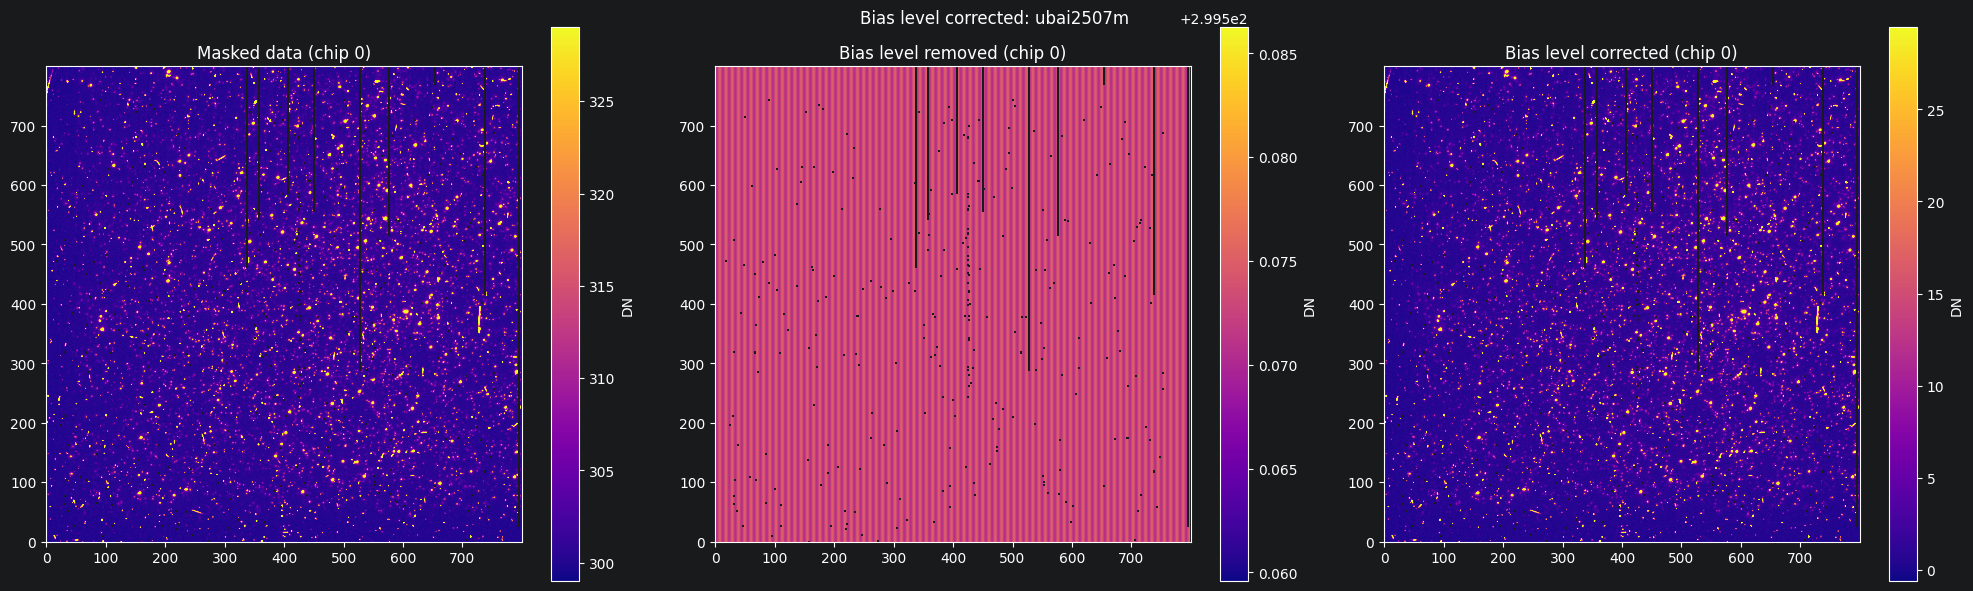

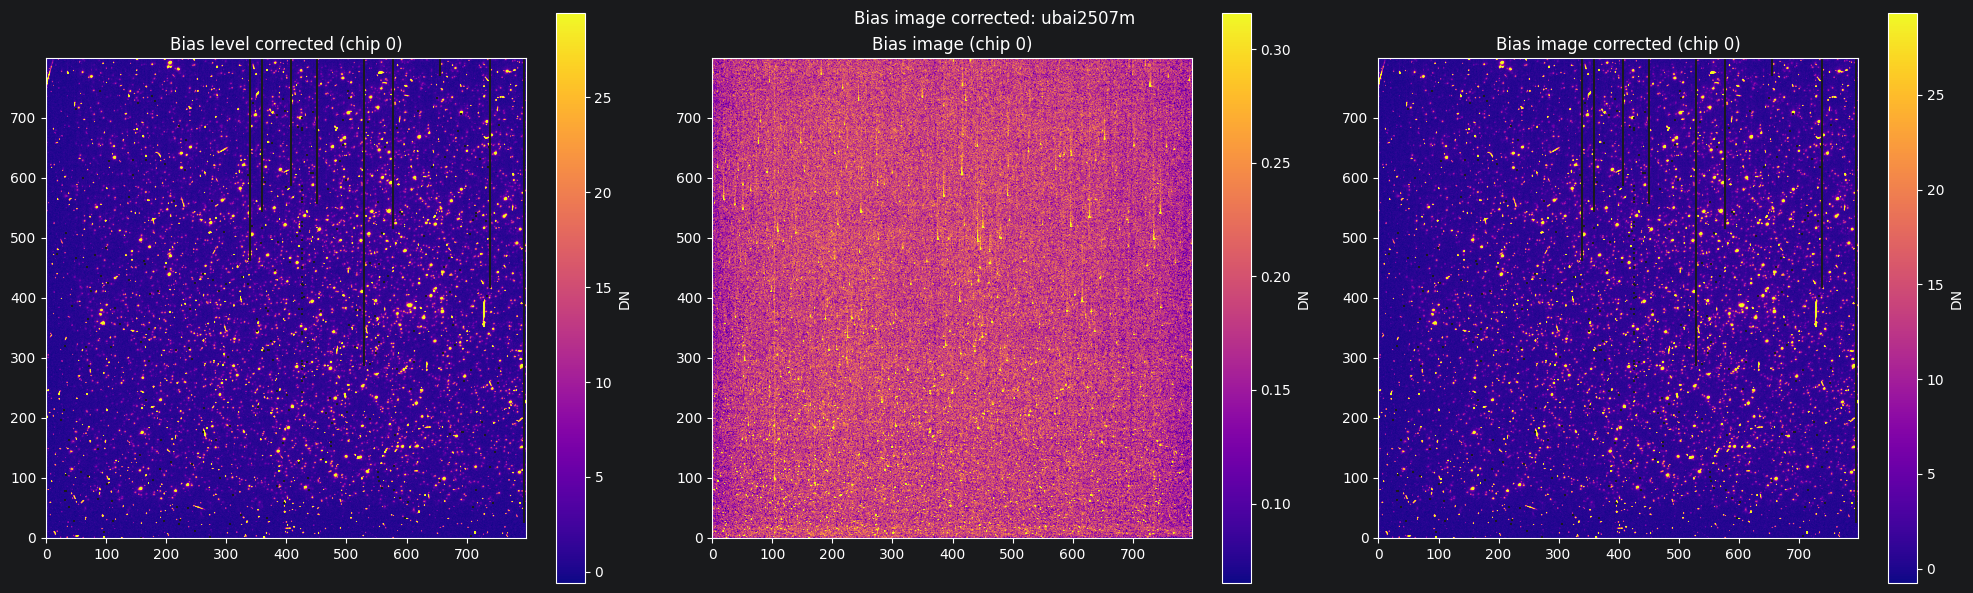

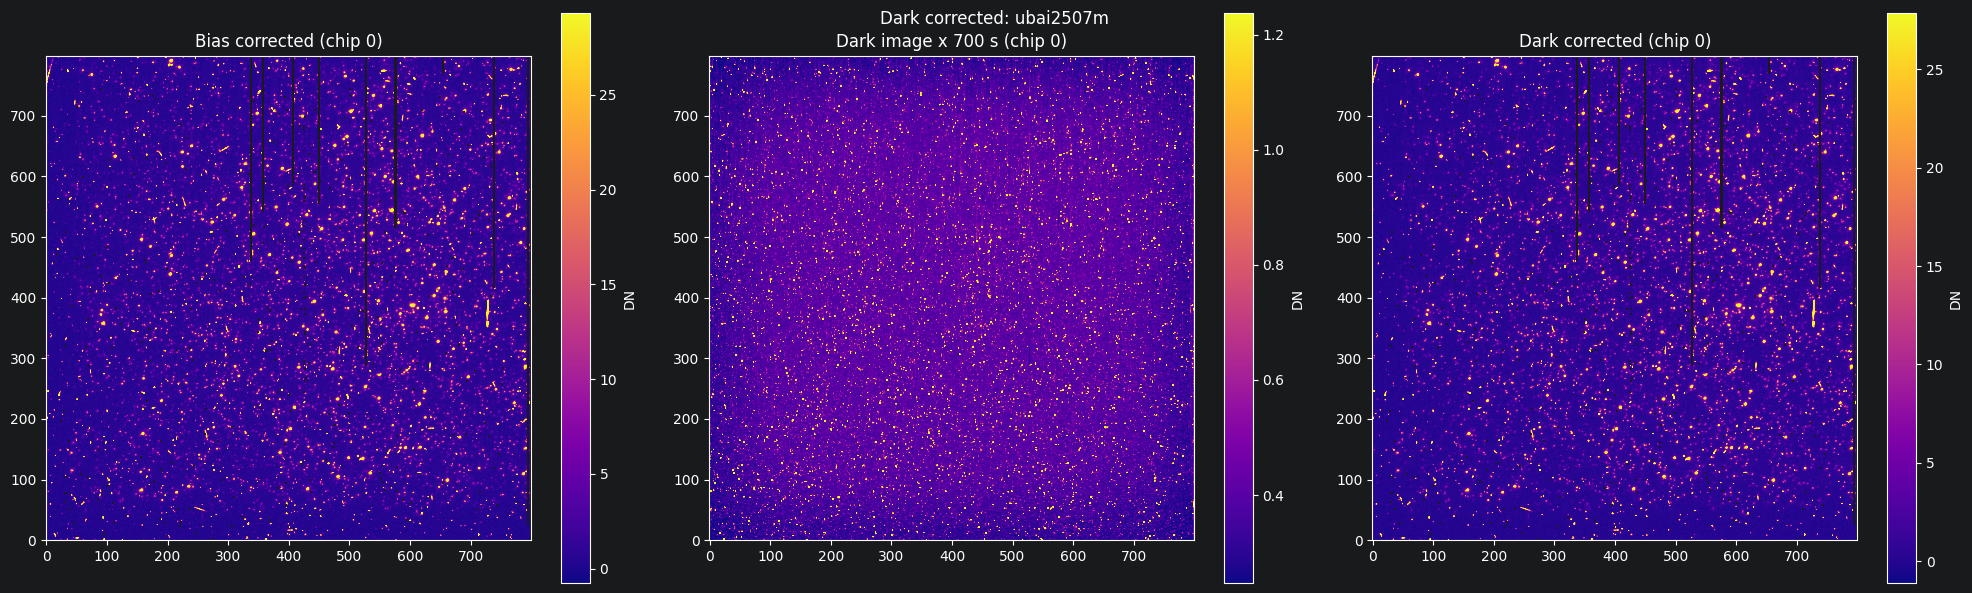

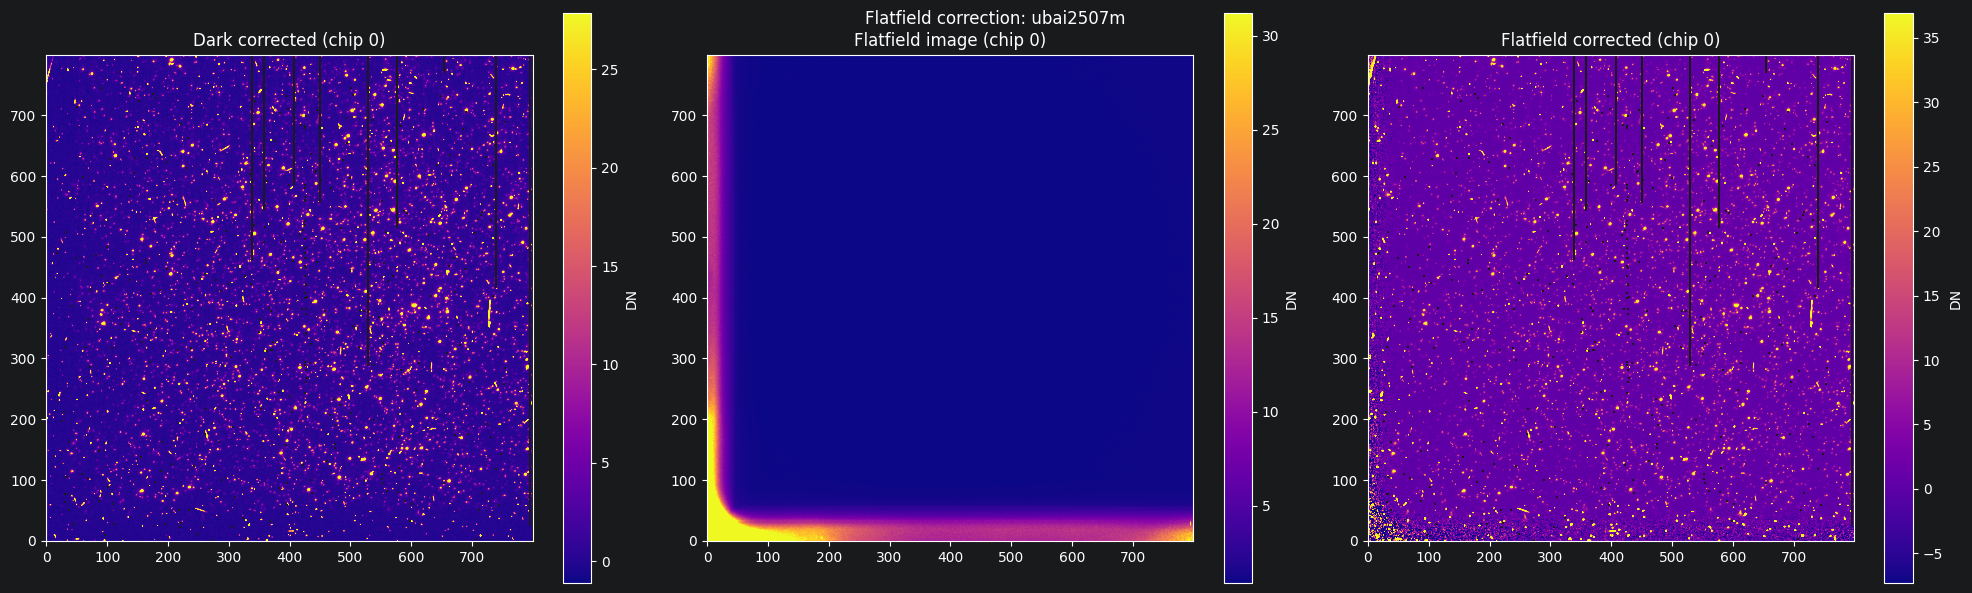

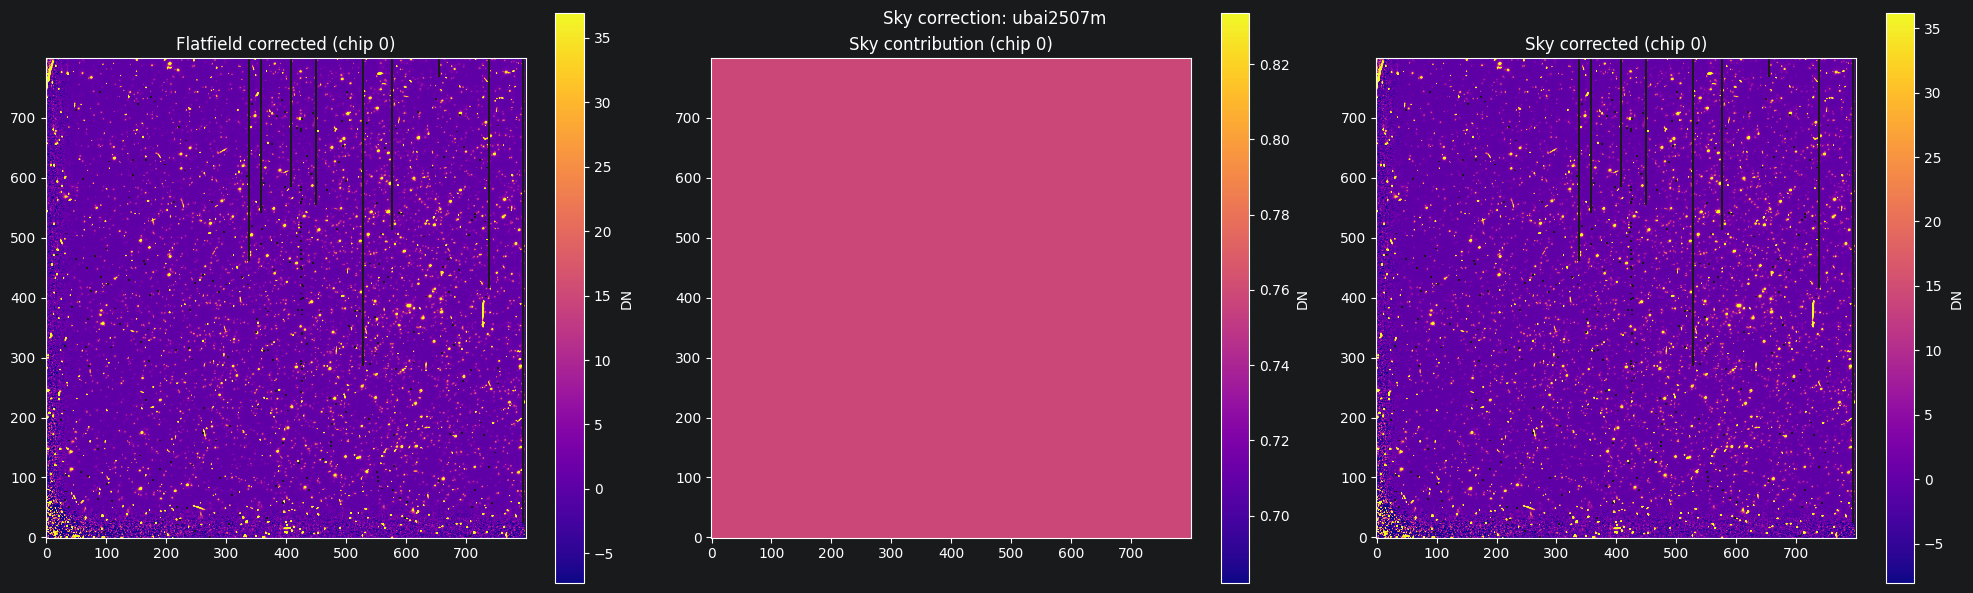

Saved images to: /Users/palakshi/Documents/GitHub/SDL-Python-Assignment/Assignment_2/HST/calibration_plots


In [292]:
# 1. Load every file of the exposure (dict of (header, data) tuples)
# exposure = get_exposure(2505)

# 2. Run the full calibration (returns the (4, y, x) sky-subtracted cube)
calibrated_data = calibrate_total(exposure)

# 3. Print statistics and make/save the plots
stages = report_intermediate_results(
    exposure,
    exposure_name,                 # label used in titles and filenames
    calibrated=calibrated_data,  # optional consistency check
    out_dir=out_plots_dir,           # optional: saves 5 PNGs here
    chip=0,                      # which chip to plot
    show=True,                   # display in the notebook
)

print("Saved images to:", (out_plots_dir).resolve())


#### 9. Show Differences
----

From the differences between

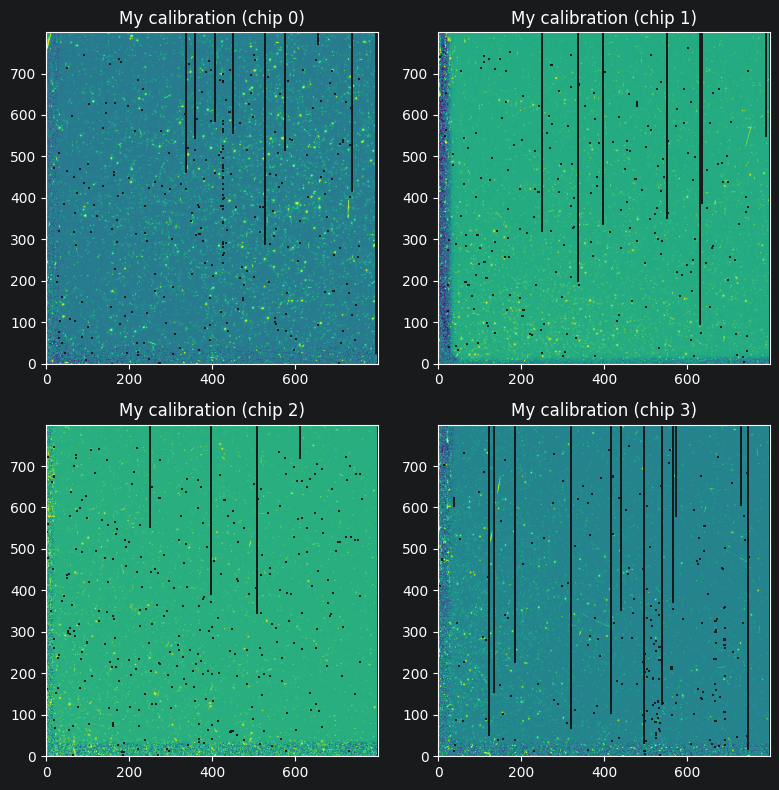

In [293]:
# My calibrated chips
fig, axes = plt.subplots(2, 2, figsize=(8, 8))
for chip, ax in enumerate(axes.ravel()):
    ax.imshow(transform_by("sqrt", calibrated_data[chip], pmin=1, pmax=99), origin="lower")
    ax.set_title(f"My calibration (chip {chip})")
fig.tight_layout()
plt.show()

In [294]:
data_file = Path("hst-processed") / "science-ready" / "F336W" / "ubai2507m_c0m_aligned.fits"
with fits.open(data_file) as hdul:
    reference = hdul[1].data.astype(float)

mine_raw = calibrated_data[0]
calibrated = transform_by("sqrt", mine_raw, pmin=1, pmax=99)
ref_display = transform_by("sqrt", reference, pmin=1, pmax=99)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

ax1.imshow(calibrated, origin="lower")
ax1.set_title("My calibration")

ax2.imshow(ref_display, origin="lower")
ax2.set_title("HST reference product")
fig.savefig(out_plots_dir/ f"{exposure_name}_CalibratedChips.png", dpi=200, bbox_inches="tight")
print("Saved image to:", (out_plots_dir/ f"{exposure_name}_CalibratedChips.png").resolve())

plt.close(fig)
plt.show()

Saved image to: /Users/palakshi/Documents/GitHub/SDL-Python-Assignment/Assignment_2/HST/calibration_plots/ubai2507m_CalibratedChips.png


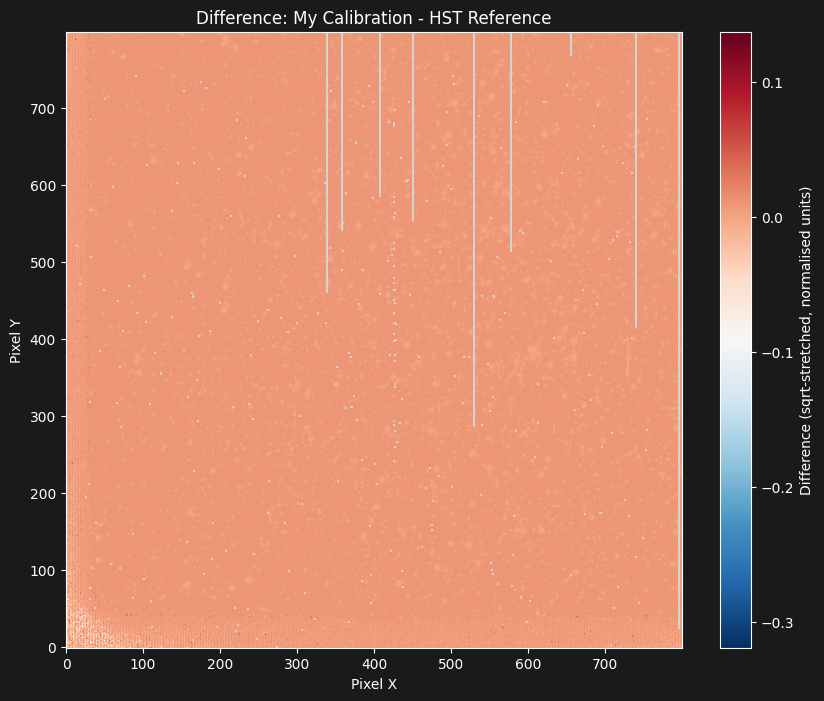

Saved image to: /Users/palakshi/Documents/GitHub/SDL-Python-Assignment/Assignment_2/HST/calibration_plots/ubai2507m_Difference.png
Valid pixels:      635890 of 640000
Mean difference:   0.0082
Median difference: 0.0091
RMS difference:    0.0095
100.0% of pixels between -0.1 and 0.1 DN


In [295]:
# Pixels that are valid in BOTH images
valid = np.isfinite(calibrated) & np.isfinite(ref_display)
difference = np.ma.masked_where(~valid, calibrated - ref_display)
cmap = plt.get_cmap("RdBu_r").copy()
cmap.set_bad("lightgrey")

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(difference, origin="lower", cmap=cmap)
fig.colorbar(im, ax=ax, label="Difference (sqrt-stretched, normalised units)")
ax.set_title("Difference: My Calibration - HST Reference")
ax.set_xlabel("Pixel X")
ax.set_ylabel("Pixel Y")

# Save the figure
save_path = out_plots_dir / f"{exposure_name}_Difference.png"
fig.savefig(save_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved image to:", (out_plots_dir/ f"{exposure_name}_Difference.png").resolve())

# Statistics on valid pixels only
d = difference.compressed()
stats_text = (
    f"Valid pixels:      {d.size} of {valid.size}\n"
    f"Mean difference:   {d.mean():.4f}\n"
    f"Median difference: {np.median(d):.4f}\n"
    f"RMS difference:    {np.sqrt(np.mean(d**2)):.4f}\n"
    f"{np.mean((d >= -0.1) & (d <= 0.1)):.1%} of pixels between -0.1 and 0.1 DN"

)
print(stats_text)

Saved image to: /Users/palakshi/Documents/GitHub/SDL-Python-Assignment/Assignment_2/HST/calibration_plots/ubai2507m_DifferenceHistogram.png


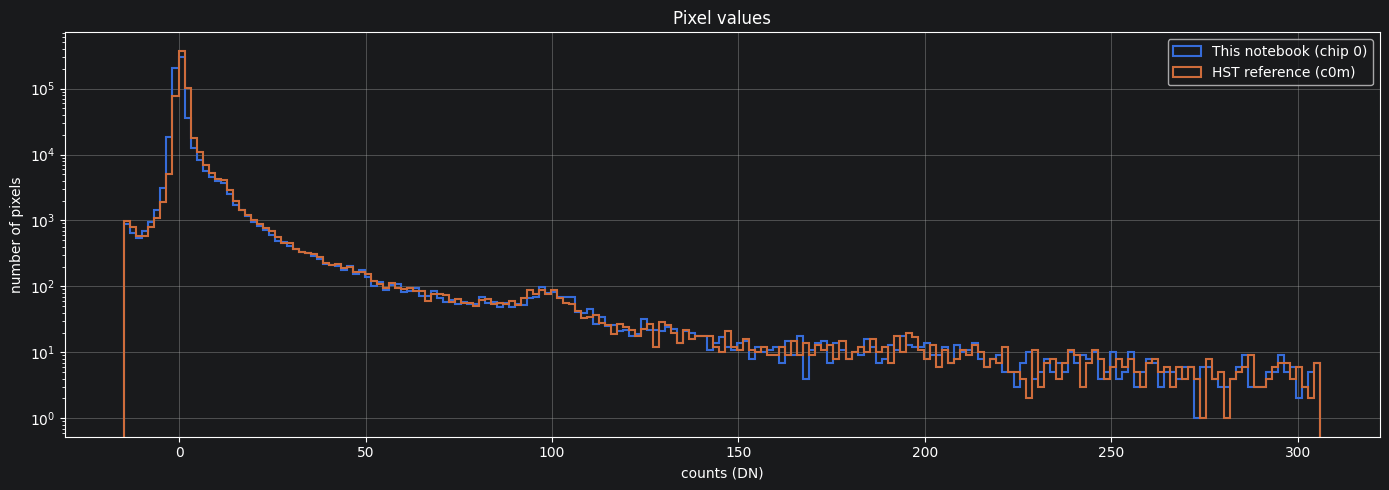

In [296]:
calibrated_img   = calibrated_data[0]      # = mine_raw
ref_img = reference               # HST c0m_aligned product

if calibrated_img.shape != ref_img.shape:
    raise ValueError(f"Grids differ: {calibrated_img.shape} vs {ref_img.shape}. "
                     "A pixel-by-pixel difference is not valid.")

# Pixel-by-pixel difference, only where both images are valid
valid = np.isfinite(calibrated_img) & np.isfinite(ref_img)
diff_img = np.where(valid,calibrated_img - ref_img, np.nan)

mine              = calibrated_img[valid]
aligned            = ref_img[valid]
difference_values = diff_img[valid]

low, high = np.percentile(np.concatenate([mine, aligned]), [0.5, 99.9])
bins = np.linspace(low, high, 200)

fig, ax = plt.subplots(figsize=(14, 5))

ax.hist(mine, bins=bins, histtype='step', lw=1.5, label='This notebook (chip 0)')
ax.hist(aligned, bins=bins, histtype='step', lw=1.5, label='HST reference (c0m)')
ax.set_yscale('log')
ax.set_xlabel('counts (DN)')
ax.set_ylabel('number of pixels')
ax.set_title('Pixel values')
ax.legend()
ax.grid()

fig.savefig(out_plots_dir / f"{exposure_name}_DifferenceHistogram.png", dpi=200, bbox_inches="tight")
print("Saved image to:", (out_plots_dir/ f"{exposure_name}_DifferenceHistogram.png").resolve())

plt.tight_layout()
plt.show()
plt.close(fig)

### 10. Photometry calibration with `PHOTTAB`
-----

`PHOTTAB` is a throughput table generated by the pipeline from the HST component throughput tables. It contains the `PHOTFLAM`, `PHOTZPT` and `ZP_CORR` keys recquired for the photometry calibration.

**Strong assumption**: `PHOTTAB` is not provided in the hst-calibration files or in the raw data. Thus, the `PHOTFLAM`, `PHOTZPT` and `ZP_CORR` keys are taken directly from the science-ready image.

Reminder from HST workshop 2:
| Keyword    | Description                                    |
|:-----------|:-----------------------------------------------|
| `PHOTFLAM` | Inverse sensitivity                            |
| `PHOTZPT`  | Zero point magnitude                           |
| `ZP_CORR`  | Delta magnitude correction for contamination   |

Calibration steps:

1. Convert the image to a ***spectral flux density*** [# photons /(s *unit energy* Area)]
    - Divide the number of photons by the exposure time to get #photons/s.
    - Multiply the result by the Inverse sentivity (`PHOTFLAM`) to obtain $F_\lambda$
2. Compute the apparent and absolute magnitude (formulas from the Course manual):
    - *Apparent magnitude*
        $$
        m_{app} = -2.5 \times \log F_\lambda + ZPP
        $$
        Where $ZPP$ is the Zero-Point Magnitude (`PHOTZPT`)

    - *Absolute magnitude*
        $$
        M_{abs} = m_{app} + 5 - 5 \log(d_{pc})
        $$
        Where $\log(d_{pc})$ is the distance to the star in parsecs.
        **Assumtion**: the given image shows the **NGC1261** cluster, at a distance of $16.4pc$


The `compute_magnitudes` function computes the apparent magnitude for the previously calibrated data, and the reference data from the aligned.fits files. The decision to use the apparent magnitude and not distance was such that we could use `PHOTFLAM` and compute the flux from counts for the refernece file. The absolute zero-point cancels in the difference, so the result tests only the calibration (bias, dark, flat, sky and PHOTFLAM). This is only the pixel magnitude, and aperture photometry would be an improved step to compare individual stars.


Reference BUNIT: COUNTS | PHOTFLAM: 1.115396e-16 | EXPTIME: 700.0
Mean flux: mine 5.218e-19, reference 5.221e-19
Valid in both: 419830, bright subset: 63679
Median dm: 0.0083 mag, std: 0.0546 mag
99.1% of bright pixels within 0.1 mag
Saved image to: /Users/palakshi/Documents/GitHub/SDL-Python-Assignment/Assignment_2/HST/calibration_plots/ubai2507m_MagintudeComparison.png


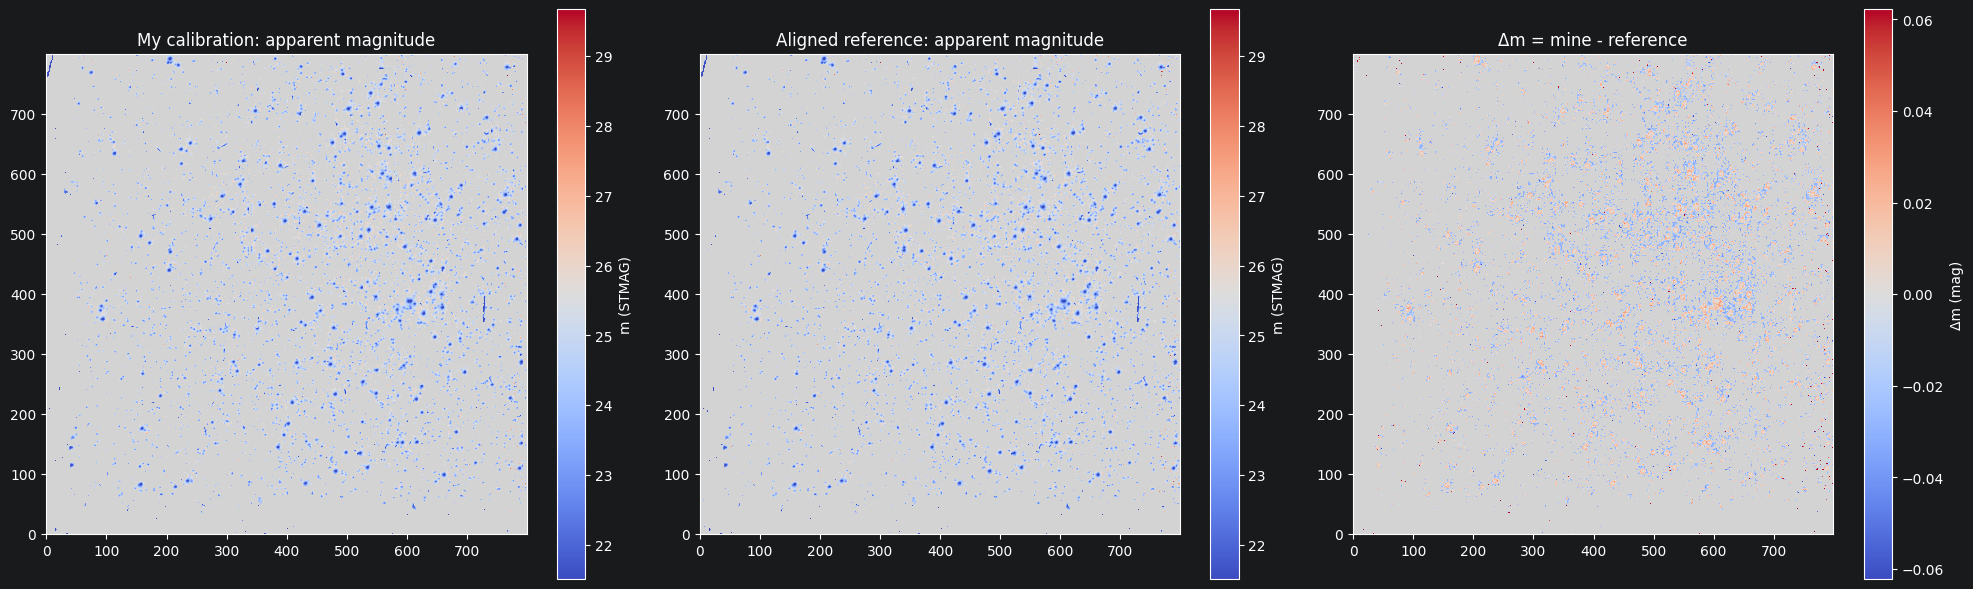

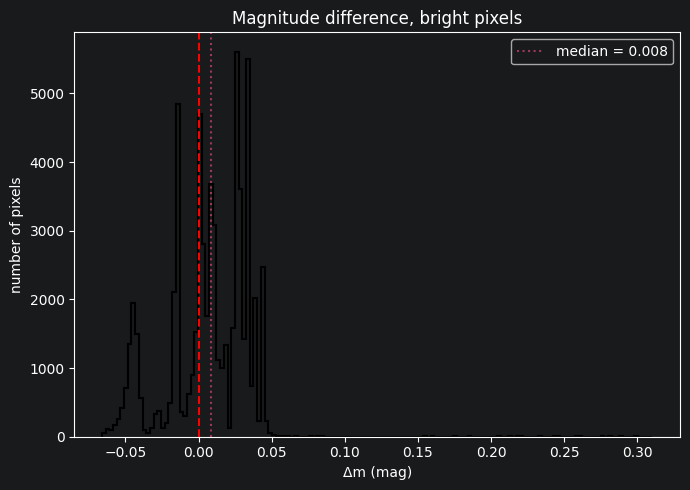

In [297]:
sky = stages["sky"]
# array of 4 values, one per chip (DN)
res, figs = compare_magnitudes(
    calibrated_data[0],                     # chip 0, sky-subtracted, DN
    data_file,
    exptime=raw_header["EXPTIME"],
    photflam=PHOTOMETRY["PHOTFLAM"],
    add_sky=sky[0],                         # put the sky back
    bright_percentile=90,
    plot=True,
)
figs["maps"].savefig(out_plots_dir / f"{exposure_name}_MagMaps.png", dpi=200, bbox_inches="tight")
figs["hist"].savefig(out_plots_dir / f"{exposure_name}_MagHist.png", dpi=200, bbox_inches="tight")

print("Saved image to:", (out_plots_dir/ f"{exposure_name}_MagintudeComparison.png").resolve())

plt.tight_layout()
plt.show()
plt.close("all")

### 11. Analysis and Results for ubai2025m - Chip 0

Here, quantitative differnences have been computed for the calibrated image and the aligned reference image provided of **ubai2025m chip 0**. For the direct comparison between the aligned file and our calibration , 635,890 of 640,000 pixels are valid (99.4%). The 4,110 excluded pixels are the masked bad pixels which were identified earlier. The median of 0.0057 means the images differ by about 0.6% of the display range and 100.0% of pixels between -0.1 and 0.1 DN when only valid pixels are counted.

For the photometric calibration:

Mean flux agrees to 0.24%: 3.689×10^-19 vs 3.680×10^-19  is a ratio of 1.0024, or about 0.003 mag. The mean is dominated by bright pixels, so the overall flux scale (bias, dark, flat, PHOTFLAM) is reproduced decently accurately.

From running the notebook for different exposures, it is evident that ubai2505m aligns most accu

This notebook could be improved by running iteratively through the different raw files, and storing results for each in a script. Unfortunately, this was resulting in a high runtime, but could be mitigated through more efficient functions and parsing. By applying the calibration to the other exposures, a next step would also be to remove cosmic rays.


The intermediate results for each step of the calibration for each chip are also printed here for inspection:


------------------------
Mask statistics for ubai2505m


Chip 0: total = 640000, valid = 635890 (99.36%), defective = 1169 (0.18%), questionable = 2941 (0.46%)
Chip 1: total = 640000, valid = 635586 (99.31%), defective = 1697 (0.27%), questionable = 2717 (0.42%)
Chip 2: total = 640000, valid = 637684 (99.64%), defective = 1171 (0.18%), questionable = 1145 (0.18%)
Chip 3: total = 640000, valid = 632032 (98.75%), defective = 1393 (0.22%), questionable = 6575 (1.03%)

------------------------
Blev overscan even columns statistics:
Chip 0: mean = 299.61, median = 300.00, std = 0.54, min = 298.00, max = 301.00
Chip 1: mean = 319.95, median = 320.00, std = 0.33, min = 319.00, max = 321.00
Chip 2: mean = 313.48, median = 313.00, std = 0.58, min = 311.00, max = 316.00
Chip 3: mean = 298.77, median = 299.00, std = 0.55, min = 297.00, max = 302.00

------------------------
Blev overscan odd columns statistics:
Chip 0: mean = 299.58, median = 300.00, std = 0.54, min = 298.00, max = 301.00
Chip 1: mean = 319.96, median = 320.00, std = 0.34, min = 319.00, max = 321.00
Chip 2: mean = 313.48, median = 313.00, std = 0.57, min = 312.00, max = 316.00
Chip 3: mean = 298.75, median = 299.00, std = 0.55, min = 297.00, max = 301.00

------------------------
Masked data statistics:
Chip 0: mean = 302.03, median = 301.00, std = 14.58, min = 292.00, max = 3055.00
Chip 1: mean = 321.72, median = 321.00, std = 15.59, min = 318.00, max = 4095.00
Chip 2: mean = 315.11, median = 314.00, std = 10.84, min = 311.00, max = 2453.00
Chip 3: mean = 301.15, median = 300.00, std = 15.07, min = 297.00, max = 4095.00

------------------------
Bias level corrected statistics:
Chip 0: mean = 2.43, median = 1.39, std = 14.58, min = -7.58, max = 2755.42
Chip 1: mean = 1.76, median = 1.04, std = 15.59, min = -1.96, max = 3775.05
Chip 2: mean = 1.63, median = 0.52, std = 10.84, min = -2.48, max = 2139.52
Chip 3: mean = 2.39, median = 1.23, std = 15.07, min = -1.77, max = 3796.23

------------------------
Bias image statistics:
Chip 0: mean = 0.19, median = 0.18, std = 0.17, min = -0.10, max = 91.15
Chip 1: mean = 0.15, median = 0.15, std = 0.19, min = -0.08, max = 64.59
Chip 2: mean = 0.19, median = 0.18, std = 0.32, min = -0.12, max = 200.41
Chip 3: mean = 0.20, median = 0.19, std = 0.40, min = -0.25, max = 164.52

------------------------
Bias image corrected statistics:
Chip 0: mean = 2.24, median = 1.19, std = 14.53, min = -7.76, max = 2755.28
Chip 1: mean = 1.61, median = 0.83, std = 15.55, min = -10.53, max = 3774.91
Chip 2: mean = 1.44, median = 0.38, std = 10.74, min = -2.71, max = 2139.33
Chip 3: mean = 2.19, median = 1.04, std = 14.94, min = -2.05, max = 3796.12

------------------------
Dark data * darktime (700.0s) statistics:
Chip 0: mean = 0.46, median = 0.37, std = 2.75, min = 0.00, max = 708.50
Chip 1: mean = 0.37, median = 0.28, std = 2.88, min = 0.00, max = 688.80
Chip 2: mean = 0.46, median = 0.35, std = 2.71, min = 0.00, max = 691.06
Chip 3: mean = 0.43, median = 0.34, std = 3.13, min = 0.00, max = 710.88

------------------------
Dark corrected statistics:
Chip 0: mean = 1.78, median = 0.79, std = 14.05, min = -14.82, max = 2754.85
Chip 1: mean = 1.24, median = 0.43, std = 15.23, min = -26.38, max = 3774.64
Chip 2: mean = 0.99, median = 0.05, std = 10.24, min = -17.73, max = 2138.95
Chip 3: mean = 1.77, median = 0.68, std = 14.33, min = -235.90, max = 3795.77

------------------------
Flatfield data statistics:
Chip 0: mean = 2.79, median = 0.96, std = 8.37, min = 0.05, max = 131.80
Chip 1: mean = 6.29, median = 1.02, std = 21.24, min = 0.01, max = 148.93
Chip 2: mean = 5.93, median = 1.02, std = 18.34, min = 0.10, max = 150.96
Chip 3: mean = 7.50, median = 1.02, std = 22.52, min = 0.01, max = 147.38

------------------------
Flatfield corrected statistics:
Chip 0: mean = 2.32, median = 0.75, std = 41.07, min = -334.01, max = 10971.29
Chip 1: mean = 2.83, median = 0.44, std = 376.98, min = -642.40, max = 264339.88
Chip 2: mean = 3.27, median = 0.06, std = 148.39, min = -1655.15, max = 40456.75
Chip 3: mean = 4.99, median = 0.69, std = 172.98, min = -571.37, max = 44191.27

Sky level per chip (DN): [ 0.722 -0.242  0.026  0.667]

------------------------
Final calibrated (sky subtracted) statistics:
Chip 0: mean = 1.59, median = 0.03, std = 41.07, min = -334.73, max = 10970.56
Chip 1: mean = 3.08, median = 0.69, std = 376.98, min = -642.15, max = 264340.12
Chip 2: mean = 3.24, median = 0.03, std = 148.39, min = -1655.17, max = 40456.73
Chip 3: mean = 4.32, median = 0.03, std = 172.98, min = -572.04, max = 44190.60
